# 04 · Comparativa

No entrena: solo lee `results/` y reúne los resultados de los notebooks 00–03.

**1.** Entorno, baselines y DQN · **2.** A3C · **3.** Más allá de los mínimos · **4.** Comparativa final (rendimiento y convergencia) · **5.** Análisis crítico y conclusiones

**Cómo leer las cifras.** Retorno mediano en las 200 series de test (DQN y A3C: mediana entre 5 semillas). Por encima de +100 % se da el múltiplo del capital (x630,4 = el capital se multiplica por 630,4); por debajo, el porcentaje con signo. Mercados: **1** tendencia + ciclo · **2** browniano · **3** reversión a la media · **4** regímenes. *Margen de ruido* (D-2.3): 25 % del múltiplo en el 1 (0,223 en log), 10 puntos en el 2 y el 4 y 2 puntos en el 3; un cambio solo se adopta si lo supera.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import ticker
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle

from common.markets import MARKETS
from common.protocol import N_STEPS, RESULTS_DIR, load_results
from common.style import AGENT_COLORS, MARKET_COLORS, MARKET_LABELS, formato, savefig, setup
from common.tuning import MARGEN, margen_log, mejora_de_verdad

setup()

MERCADOS = list(MARKETS)
CORTO = {m: MARKET_LABELS[m].split(" · ")[0] for m in MERCADOS}
NOMBRES = {"aleatorio": "Aleatorio", "buy_hold": "Buy & hold", "no_operar": "No operar", "regla_tendencia": "Regla tendencia",
           "regla_reversion": "Regla reversión", "qlearning": "Q-Learning (T1)", "sarsa": "SARSA (T1)", "dqn": "DQN", "a3c": "A3C"}
MEJOR_REF = {"tendencia_ciclo": "regla_tendencia", "browniano": "no_operar", "reversion_media": "regla_reversion", "regimenes": "no_operar"}


def csv(nombre):
    return pd.read_csv(RESULTS_DIR / f"{nombre}.csv")


def heatmap(ax, puntos, textos, filas, cabeceras, separadores=(), lim=4):
    # Mapa de calor en márgenes de ruido: |valor| < 1 es ruido; > +1 sería una mejora adoptable
    im = ax.imshow(puntos, cmap="RdBu", norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim), aspect="auto")
    for i in range(puntos.shape[0]):
        for j in range(puntos.shape[1]):
            ax.text(j, i, textos[i][j], ha="center", va="center", fontsize=8.5,
                    fontweight="bold" if puntos[i, j] > 1 else "normal", color="white" if abs(puntos[i, j]) > 0.7 * lim else "black")
    ax.set_xticks(range(len(cabeceras)), cabeceras, fontsize=9)
    for k, lab in enumerate(ax.get_xticklabels()):
        lab.set_color(MARKET_COLORS[MERCADOS[k]])
    ax.set_yticks(range(len(filas)), filas)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    ax.grid(False)
    for s in separadores:
        ax.axhline(s - 0.5, color="white", lw=3)
    for sp in ax.spines.values():
        sp.set_visible(False)
    return im


# Resultados oficiales en test (00, 01, 02 y tabulares del Taller 1) y semillas de DQN y A3C
tabulares = csv("taller1_tabular").query("agente in ['qlearning', 'sarsa']")
oficial = load_results().query("fuente in ['00_baselines', '01_dqn', '02_a3c']")  # sin los extras del 03
RES = pd.concat([oficial, tabulares], ignore_index=True)
ORDEN = [a for a in AGENT_COLORS if a in set(RES.agente)]
TABLA = RES.pivot(index="agente", columns="mercado", values="retorno_mediana").loc[ORDEN, MERCADOS]
SEMILLAS = pd.concat([csv("01_grid_final"), csv("02_grid_final")], ignore_index=True)

## 1. Entorno, baselines y DQN

Resumen de `00_entorno_y_baselines` y `01_dqn`.

### 1.1 Referencias: qué hay que batir

- **Aleatorio y buy & hold** (las pide el enunciado). El aleatorio hace ~165 operaciones por episodio y solo gana en el mercado 1 (x4,3). Buy & hold da x33,6 en el 1 y pierde en los otros tres.
- **No operar** (+0,0 %): bate a buy & hold en los mercados 2–4; es lo óptimo donde no hay señal.
- **Reglas de un umbral** (tendencia y reversión), elegido en validación. Superan a los tabulares del Taller 1 (x630,4 frente a x502,3 en el 1; +29,2 % frente a +27,0 % en el 3), pero cada una solo sirve en su mercado (la de reversión pierde un 50,1 % en el 1).
- **Q-Learning y SARSA del Taller 1**, en las mismas series de test: comparan una red con una tabla Q que ve el mismo estado.
- **Listón real por mercado: x630,4 · +0,0 % · +29,2 % · +0,0 %**, no buy & hold.

### 1.2 Hiperparámetros de DQN

Red 2 → 64 → 3, memoria de 20 000 transiciones, minibatch de 128 y red objetivo copiada cada 500 pasos. **Configuración elegida, igual en los 4 mercados:**

| α (Adam) | γ | ε | Episodios |
|---|---|---|---|
| 1e-3 | 0,9 | de 1, ×0,995 por episodio (0,08 al acabar) | 500 (≈ 247 000 pasos) |

Ajuste por etapas (D-2.3): un parámetro cada vez, 100 series de validación y 3 semillas.

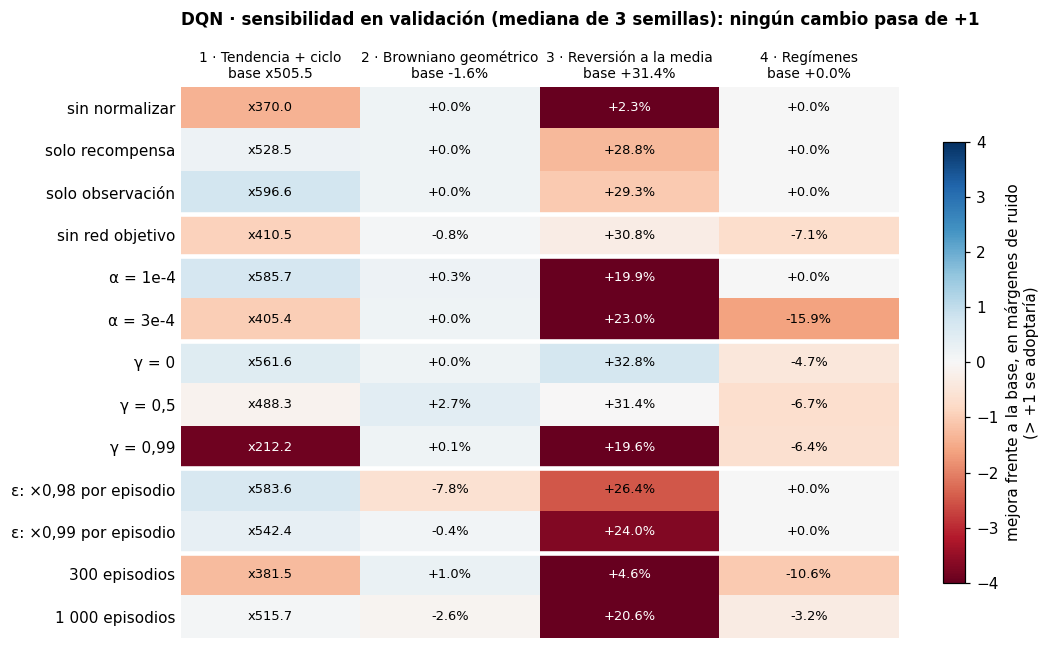

In [2]:
norm = csv("01_grid_normalizacion")
base_dqn = norm[norm.normalize_obs & norm.normalize_reward].groupby("mercado").retorno_mediana.median()
FILAS_DQN = [  # (etiqueta, fichero, filtro)
    ("sin normalizar", "01_grid_normalizacion", "normalize_obs == False and normalize_reward == False"),
    ("solo recompensa", "01_grid_normalizacion", "normalize_obs == False and normalize_reward == True"),
    ("solo observación", "01_grid_normalizacion", "normalize_obs == True and normalize_reward == False"),
    ("sin red objetivo", "01_grid_objetivo", "use_target == False"),
    ("α = 1e-4", "01_grid_lr", "lr == 0.0001"),
    ("α = 3e-4", "01_grid_lr", "lr == 0.0003"),
    ("γ = 0", "01_grid_gamma", "gamma == 0"),
    ("γ = 0,5", "01_grid_gamma", "gamma == 0.5"),
    ("γ = 0,99", "01_grid_gamma", "gamma == 0.99"),
    ("ε: ×0,98 por episodio", "01_grid_epsilon", "epsilon_decay == 0.98"),
    ("ε: ×0,99 por episodio", "01_grid_epsilon", "epsilon_decay == 0.99"),
    ("300 episodios", "01_grid_episodios", "n_episodes == 300"),
    ("1 000 episodios", "01_grid_episodios", "n_episodes == 1000"),
]


def en_margenes(m, nuevo, base):
    # Mejora sobre la base dividida por el margen de ruido del mercado (D-2.3)
    if m == "tendencia_ciclo":
        return np.log((1 + nuevo) / (1 + base)) / margen_log(m)
    return (nuevo - base) / MARGEN[m]


vals = np.array([[csv(f).query(q).query("mercado == @m").retorno_mediana.median() for m in MERCADOS] for _, f, q in FILAS_DQN])
puntos = np.array([[en_margenes(m, v, base_dqn[m]) for m, v in zip(MERCADOS, fila)] for fila in vals])

fig, ax = plt.subplots(figsize=(10, 6))
im = heatmap(ax, puntos, [[formato(v) for v in fila] for fila in vals], [f for f, _, _ in FILAS_DQN],
             [f"{MARKET_LABELS[m]}\nbase {formato(base_dqn[m])}" for m in MERCADOS], separadores=(3, 4, 6, 9, 11))
fig.colorbar(im, ax=ax, shrink=0.8, label="mejora frente a la base, en márgenes de ruido\n(> +1 se adoptaría)")
ax.set_title("DQN · sensibilidad en validación (mediana de 3 semillas): ningún cambio pasa de +1", loc="left", pad=40)
fig.tight_layout()
savefig(fig, "04_p1_sensibilidad")
plt.show()

- **Ningún cambio supera el margen en ningún mercado**: se queda la configuración de partida (no prueba que sea óptima, solo que el ruido no la distingue).
- **Normalizar es imprescindible en reversión**: sin nada, +2,3 % (apenas opera); con observación y recompensa normalizadas, +31,4 %.
- **γ = 0,99 es lo único claramente peor** donde hay señal (x212,2 y +19,6 %); entre 0 y 0,9 da igual: basta un horizonte corto.
- **300 episodios son pocos** en el 3 (+4,6 %) y 1 000 no mejoran.

### 1.3 DQN en test

Barras y semillas en la **figura de §4.1**.

- **Bate a buy & hold y al aleatorio donde hay señal**: x299,8 frente a x33,6 en el 1; +20,5 % frente a −0,3 % en el 3.
- **No alcanza a las reglas ni a los tabulares**: x299,8 frente a x630,4 (regla) y x502,3 (Q-Learning); +20,5 % frente a +29,2 % y +27,0 %. Serie a serie, la regla le gana en el 74 % de las series del 1 y en el 63 % de las del 3.
- **Sin señal, lo mejor sigue siendo no operar**: −3,9 % en el 2 (≈ buy & hold, −3,5 %) y +0,0 % en el 4, aunque 2 de 5 semillas pierden (−7,9 % y −3,7 %).
- **Mucha dispersión entre semillas**: de x228,4 a x557,8 en el 1 y de +4,7 % a +26,3 % en el 3.
- **Se confirma fuera del test**: en 400 series nuevas, x287,4 · −6,1 % · +24,5 % · +0,0 %, frente a x530,2 · 0 % · +32,7 % · 0 % de las referencias.

### 1.4 ¿Aprende la estrategia esperada?

Ventaja de operar frente a mantener según la tendencia (por encima de cero, opera): arriba sin activo (comprar), abajo con activo (vender). Figura de `01_dqn` §5.

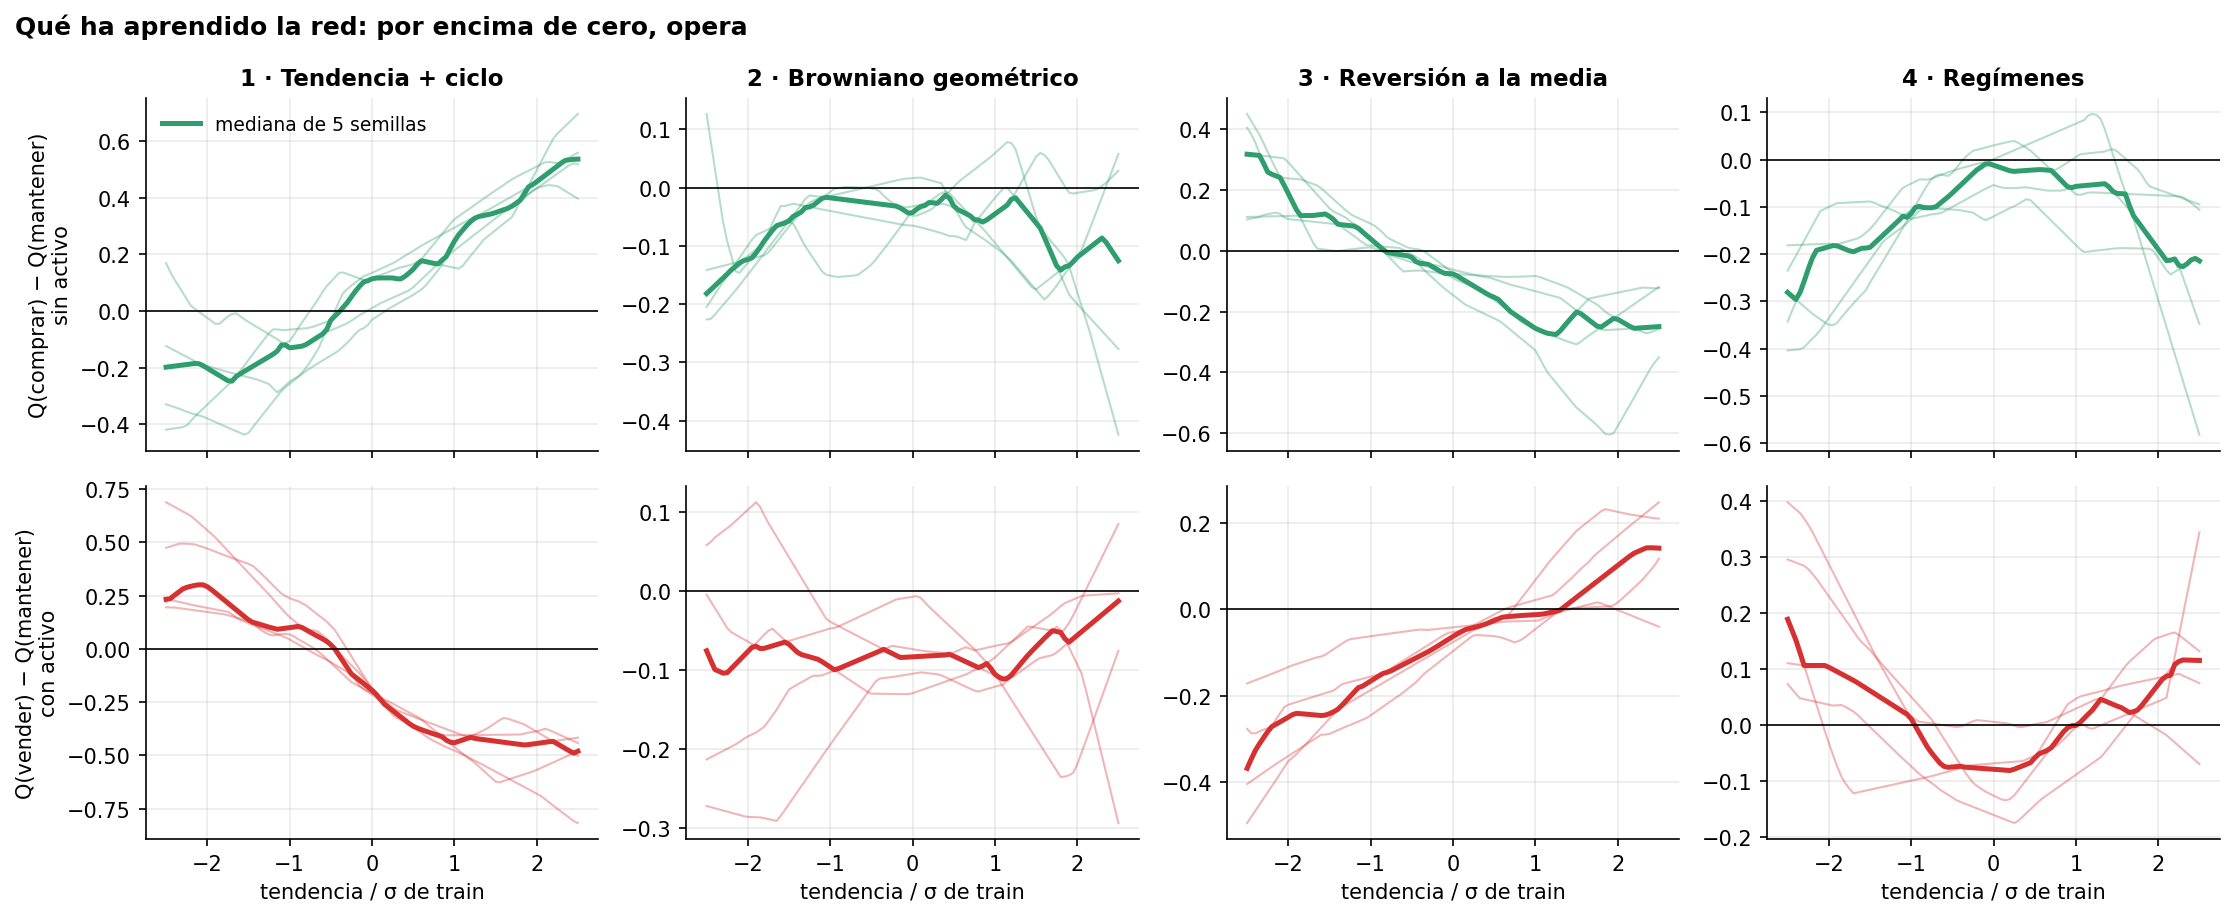

In [3]:
display(Image(filename=str(RESULTS_DIR / "figures" / "01_politica.png"), width=900))

| Mercado | Esperada | Aprendida por DQN |
|---|---|---|
| 1 · Tendencia | Seguir la tendencia | **Sí**, en las 5 semillas, pero opera de más: 44 operaciones dan x557,8 y 69, x228,4 (la regla hace 41) |
| 2 · Browniano | No operar | **No**: entra y se queda. La recompensa suma retornos simples (+0,0001 por paso), pero el capital compone (−0,0001) |
| 3 · Reversión | Comprar tras caídas, vender tras subidas | **Sí**, con umbrales cerca de ±1 σ. Una semilla casi no vende (+4,7 %) |
| 4 · Regímenes | No operar | **En parte**: 3 de 5 semillas no operan; las otras venden ante movimientos grandes en cualquier sentido (forma de U) y pierden |

### 1.5 Mejoras probadas en el 01

Elegidas solo en validación (el test ya se había visto, D-2.4), con 5 semillas y comparando **serie a serie, en log**, frente al DQN base.

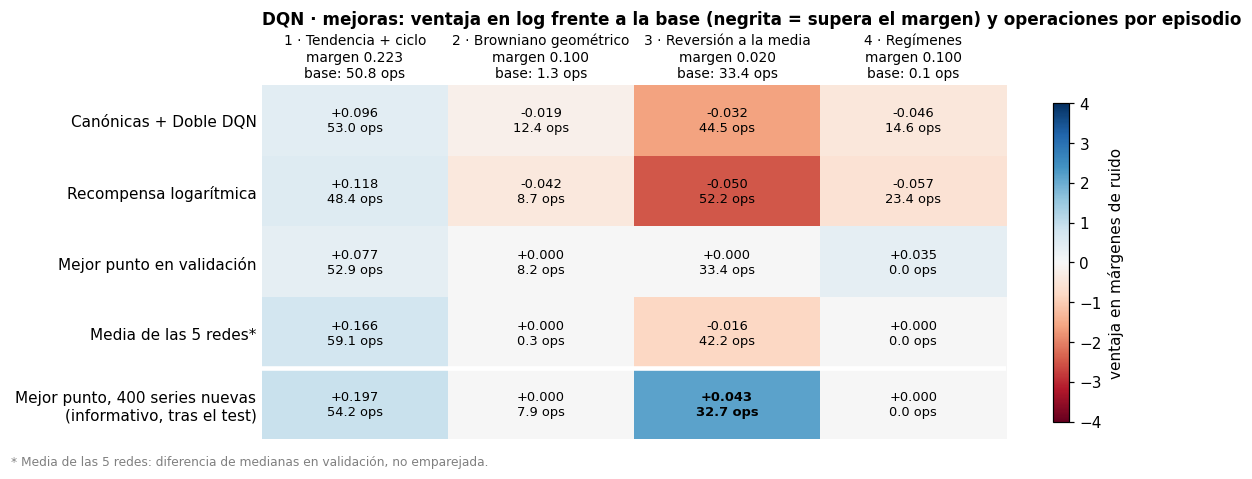

In [4]:
# Ventaja emparejada (mediana entre semillas de la mediana por serie de log(1+r) − log(1+r_base)), copiada de la salida
# de 01_dqn §7: necesita los retornos por serie, que solo están en la caché no versionada. Las operaciones salen de los CSV.
VENTAJA_DQN = {
    "canónicas + Doble": [0.096, -0.019, -0.032, -0.046],
    "recompensa log": [0.118, -0.042, -0.050, -0.057],
    "mejor punto": [0.077, 0.000, 0.000, 0.035],
    "mejor punto · nuevas": [0.197, 0.000, 0.043, 0.000],
}
ops_var = csv("01_grid_mejora_variantes").groupby(["variante", "mercado"]).n_trades.median()
ops_base = csv("01_grid_mejora_base").groupby("mercado").n_trades.median()
conj = csv("01_grid_mejora_conjunto").set_index("mercado")
sueltos = csv("01_grid_mejora_sueltos").groupby("mercado").retorno_mediana.median()
ops_nuevas = csv("01_grid_mejora_mejor_punto_nuevas").groupby("mercado").n_trades.median()

MEJORAS_DQN = {  # fila: (ventaja en log por mercado, operaciones por episodio por mercado)
    "Canónicas + Doble DQN": (VENTAJA_DQN["canónicas + Doble"], [ops_var["canónicas + Doble", m] for m in MERCADOS]),
    "Recompensa logarítmica": (VENTAJA_DQN["recompensa log"], [ops_var["recompensa log", m] for m in MERCADOS]),
    "Mejor punto en validación": (VENTAJA_DQN["mejor punto"], [ops_var["mejor punto", m] for m in MERCADOS]),
    "Media de las 5 redes*": ([np.log1p(conj.retorno_mediana[m]) - np.log1p(sueltos[m]) for m in MERCADOS],
                              [conj.n_trades[m] for m in MERCADOS]),
    "Mejor punto, 400 series nuevas\n(informativo, tras el test)": (VENTAJA_DQN["mejor punto · nuevas"], [ops_nuevas[m] for m in MERCADOS]),
}

puntos = np.array([[d / margen_log(m) for d, m in zip(v, MERCADOS)] for v, _ in MEJORAS_DQN.values()])
textos = [[f"{d:+.3f}\n{o:.1f} ops" for d, o in zip(v, ops)] for v, ops in MEJORAS_DQN.values()]
fig, ax = plt.subplots(figsize=(11, 4.2))
im = heatmap(ax, puntos, textos, list(MEJORAS_DQN),
             [f"{MARKET_LABELS[m]}\nmargen {margen_log(m):.3f}\nbase: {ops_base[m]:.1f} ops" for m in MERCADOS], separadores=(4,))
fig.colorbar(im, ax=ax, shrink=0.9, label="ventaja en márgenes de ruido")
ax.set_title("DQN · mejoras: ventaja en log frente a la base (negrita = supera el margen) y operaciones por episodio", loc="left", pad=40)
fig.text(0.01, -0.02, "* Media de las 5 redes: diferencia de medianas en validación, no emparejada.", fontsize=8, color="grey")
fig.tight_layout()
savefig(fig, "04_p1_mejoras")
plt.show()

- **Ninguna supera el margen en validación**: el DQN oficial sigue siendo el base.
- **Canónicas + Doble y recompensa log hacen lo contrario de lo esperado**: operan más donde no hay señal (8,7–23,4 operaciones frente a 0,1–1,3 en los mercados 2 y 4) y pierden.
- **Media de las 5 redes**: x596,8 frente a x505,5 en el 1 (+18 %, por debajo del 25 %) y peor en el 3 (+25,6 % frente a +27,7 %).
- **Mejor punto en validación, la única prometedora**: en 400 series nuevas pasa de x287,4 a x356,7 y de +24,5 % a +29,6 % (supera el margen en el 3) y elimina las semillas malas (peor del 3: de +5,4 % a +24,5 %). Sigue por debajo de las reglas (x530,2 y +32,7 %) y, medida tras el test, no cambia el resultado oficial.

**En resumen:** DQN aprende la estrategia correcta donde hay señal, pero con el estado `[tendencia, posición]` no aporta nada sobre una regla de un umbral ni sobre la tabla Q del Taller 1: pierde por inestabilidad entre semillas y por operar de más.

## 2. A3C

- **A3C real** (D-2.1): 3 procesos asíncronos que escriben sin cerrojos sobre pesos y Adam compartidos. Misma entrada, red de 64 neuronas, recompensa normalizada y presupuesto que DQN: 500 episodios ≈ 247 000 pasos.
- **Sin ε**: explora muestreando π; el ajuste de ε del enunciado pasa a **β**, el peso de la entropía.
- Detalle en `02_a3c.ipynb` y D-2.6.

### 2.1 Hiperparámetros

Mismo ajuste por etapas que DQN (D-2.3), pero **por mercado**.

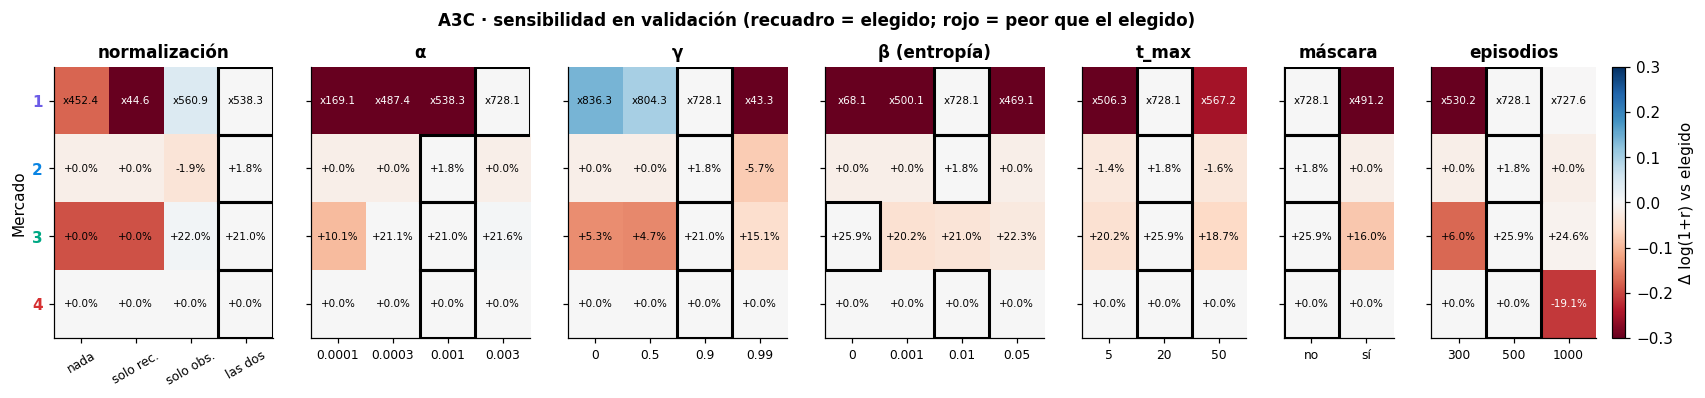

,α,γ,β,t_max,máscara,episodios,validación
1 · Tendencia + ciclo,0.003,0.9,0.01,20,no,500,x728.1
2 · Browniano geométrico,0.001,0.9,0.01,20,no,500,+1.8%
3 · Reversión a la media,0.001,0.9,0.0,20,no,500,+25.9%
4 · Regímenes,0.001,0.9,0.01,20,no,500,+0.0%


In [5]:
# Reconstruye el ajuste por etapas de 02_a3c (§3) a partir de los CSV, con la misma regla que common.tuning.Ajuste
BASE_A3C = {"lr": 0.001, "gamma": 0.9, "entropy_coef": 0.01, "t_max": 20, "mask_redundant": False, "n_episodes": 500}
norm = csv("02_grid_normalizacion")
norm["valor"] = norm.normalize_obs.map({True: "obs", False: ""}) + norm.normalize_reward.map({True: "+rec", False: ""})
norm["valor"] = norm.valor.replace({"": "nada", "obs+rec": "las dos", "+rec": "solo rec.", "obs": "solo obs."})
tab_norm = norm.groupby(["mercado", "valor"]).retorno_mediana.median().unstack()[["nada", "solo rec.", "solo obs.", "las dos"]]
actual = {m: dict(BASE_A3C) for m in MERCADOS}
punto = {m: tab_norm.loc[m, "las dos"] for m in MERCADOS}
etapas = [("normalización", None, tab_norm.loc[MERCADOS], {m: "las dos" for m in MERCADOS})]
for nombre, param, titulo in [("lr", "lr", "α"), ("gamma", "gamma", "γ"), ("entropia", "entropy_coef", "β (entropía)"),
                              ("tmax", "t_max", "t_max"), ("mascara", "mask_redundant", "máscara"), ("episodios", "n_episodes", "episodios")]:
    pts = csv(f"02_grid_{nombre}").groupby(["mercado", param]).retorno_mediana.median()
    filas = {}
    for m in MERCADOS:
        filas[m] = {actual[m][param]: punto[m], **pts[m].to_dict()}
        mejor = max(pts[m].index, key=lambda v: pts[m][v])
        if mejora_de_verdad(m, pts[m][mejor], punto[m]):
            actual[m][param], punto[m] = mejor, pts[m][mejor]
    etapas.append((titulo, param, pd.DataFrame(filas).T.loc[MERCADOS].sort_index(axis=1), {m: actual[m][param] for m in MERCADOS}))

# Color = Δ log(1 + r) frente al valor elegido en esa etapa; texto = mediana en validación
fig, axes = plt.subplots(1, len(etapas), figsize=(18.5, 3.2), gridspec_kw={"width_ratios": [t.shape[1] for _, _, t, _ in etapas]})
for k, (ax, (titulo, param, tab, elegido)) in enumerate(zip(axes, etapas)):
    ref = np.array([np.log1p(tab.loc[m, elegido[m]]) for m in MERCADOS])[:, None]
    delta = np.log1p(tab.to_numpy(dtype=float)) - ref
    im = ax.imshow(delta, cmap="RdBu", vmin=-0.3, vmax=0.3, aspect="auto")
    for i, m in enumerate(MERCADOS):
        for j, v in enumerate(tab.columns):
            ax.text(j, i, formato(tab.loc[m, v]), ha="center", va="center", fontsize=6.8,
                    color="white" if abs(delta[i, j]) > 0.2 else "black")
            if v == elegido[m]:
                ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, lw=2, ec="black"))
    cols = [{True: "sí", False: "no"}[v] if isinstance(v, (bool, np.bool_)) else f"{v:g}" if not isinstance(v, str) else v for v in tab.columns]
    ax.set_xticks(range(len(cols)), cols, fontsize=8, rotation=30 if param is None else 0)
    ax.set_yticks(range(4), [CORTO[m] for m in MERCADOS] if k == 0 else [])
    if k == 0:
        for lab, m in zip(ax.get_yticklabels(), MERCADOS):
            lab.set_color(MARKET_COLORS[m]); lab.set_fontweight("bold")
    ax.set_title(titulo)
    ax.grid(False)
axes[0].set_ylabel("Mercado")
fig.colorbar(im, ax=axes, fraction=0.012, pad=0.01, label="Δ log(1+r) vs elegido")
fig.suptitle("A3C · sensibilidad en validación (recuadro = elegido; rojo = peor que el elegido)", y=1.04, fontsize=11, fontweight="bold")
savefig(fig, "04_p2_sensibilidad")
plt.show()

pd.DataFrame({MARKET_LABELS[m]: {"α": actual[m]["lr"], "γ": actual[m]["gamma"], "β": actual[m]["entropy_coef"], "t_max": actual[m]["t_max"],
                                 "máscara": "sí" if actual[m]["mask_redundant"] else "no", "episodios": actual[m]["n_episodes"],
                                 "validación": formato(punto[m])} for m in MERCADOS}).T

- **Base**: α = 0,001, γ = 0,9, β = 0,01, `t_max` = 20, 500 episodios, sin máscara y normalizando observación y recompensa. **Solo dos cambios superan el margen**: α = 0,003 en el 1 (x538,3 → x728,1) y β = 0 en el 3 (+21,0 % → +25,9 %).
- **Normalizar la observación es imprescindible**: sin ella el 3 no opera (+0,0 %); con solo la recompensa el 1 cae a x44,6.
- **γ es lo más sensible**: γ = 0,99 hunde el 1 a x43,3; γ ≤ 0,5 deja el 3 en +5 %.
- **β sustituye a ε**: con β = 0 el 1 cae a x68,1 (necesita explorar); el 3 no.
- **2 y 4 no discriminan**: casi todo da ≈ 0 %.

### 2.2 A3C en test

Barras y semillas en la **figura de §4.1**.

- **No bate a la mejor referencia en ningún mercado**: x374,9 frente a x630,4 en el 1 y +13,8 % frente a +29,2 % en el 3; serie a serie pierde en el 68 % y el 75 % de las series.
- **Sí bate con claridad a buy & hold y al aleatorio** con señal (x374,9 frente a x33,6; +13,8 % frente a −0,3 %) y no pierde nada en regímenes (+0,0 %, 0 operaciones).
- **Dispersión alta**: en el 1 una semilla no opera (+0,0 %) y el resto va de x346,0 a x594,4; en el 3, de +2,9 % a +18,8 %.
- **Caída validación → test**: x728,1 → x374,9 y +25,9 % → +13,8 % (elegir con 3 semillas sobreajusta a validación).

### 2.3 ¿Aprende la estrategia esperada?

Probabilidad de operar según la tendencia, una curva por semilla (figura de `02_a3c` §5).

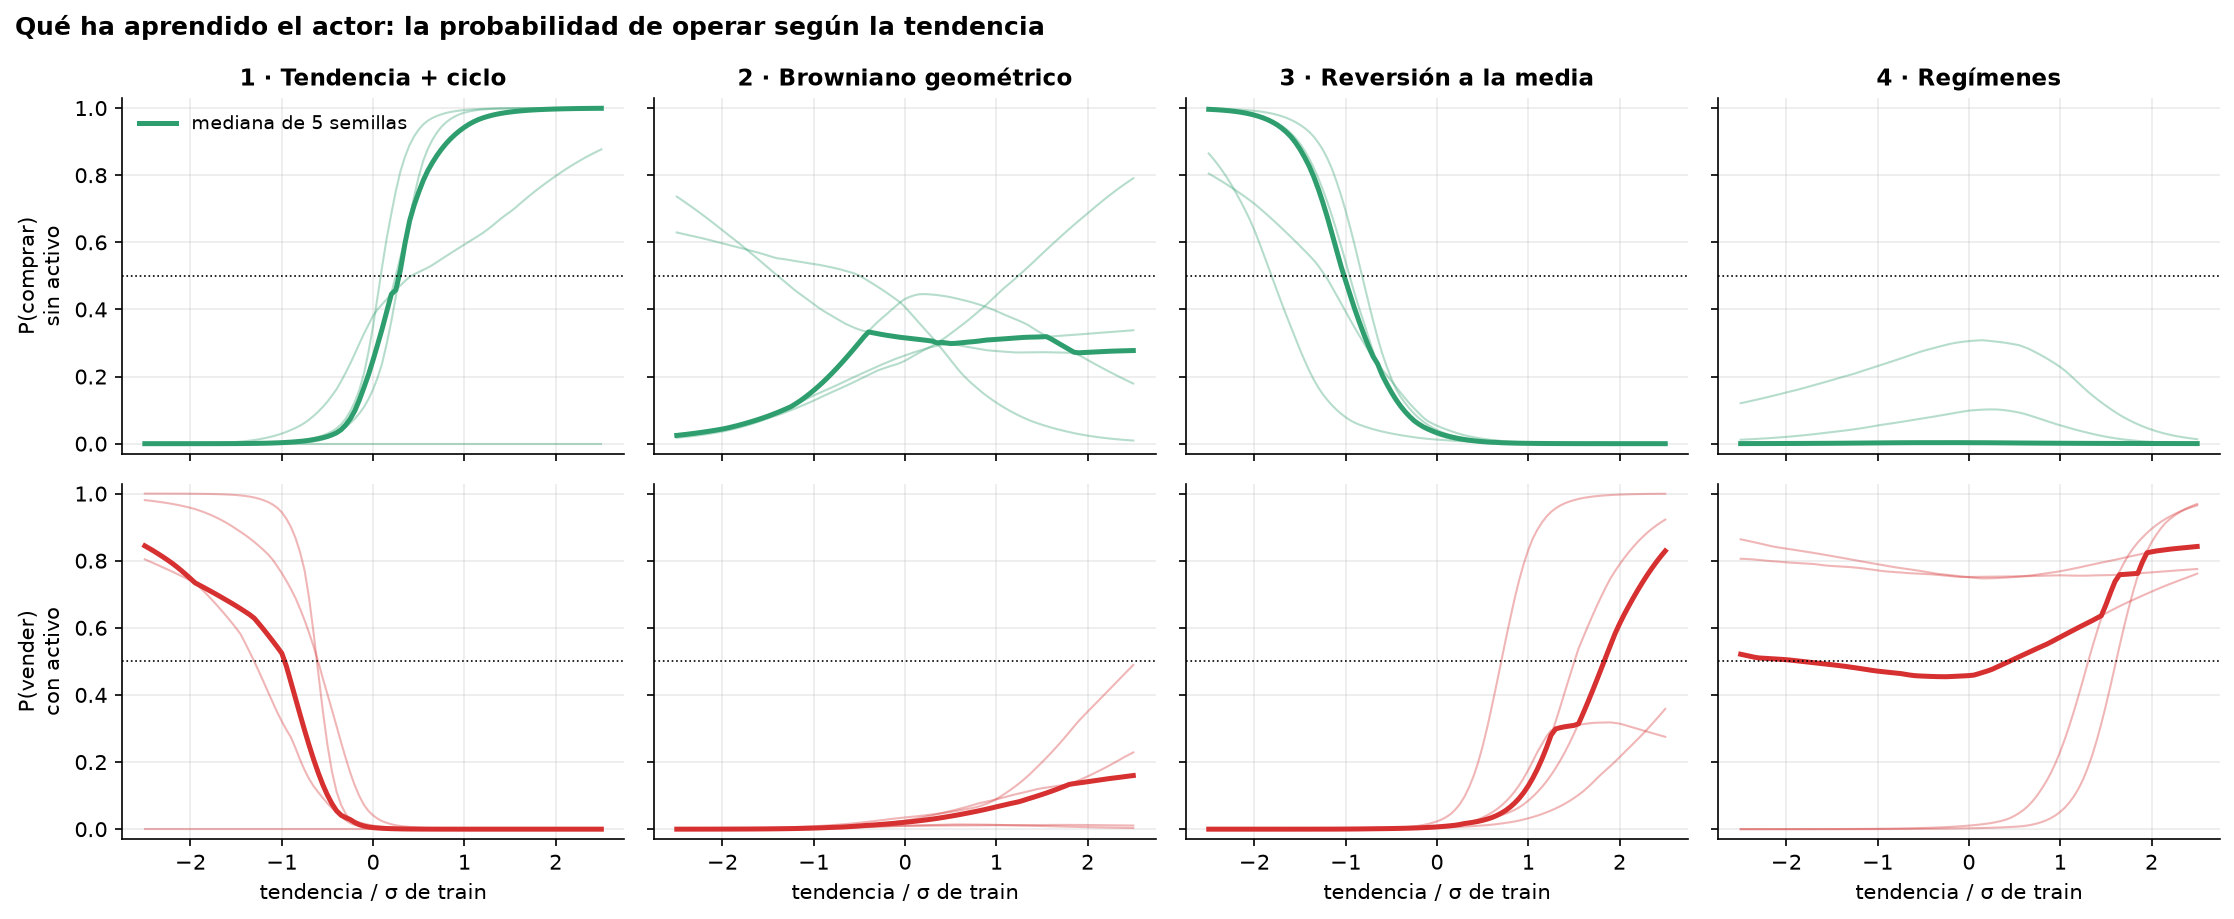

In [6]:
display(Image(filename=str(RESULTS_DIR / "figures" / "02_politica.png"), width=950))

| Mercado | Esperada | Aprendida por A3C |
|---|---|---|
| 1 · Tendencia | Seguir la tendencia | **Sí** (salvo 1 semilla): compra con tendencia > 0 y vende por debajo de ≈ −1 σ; dentro el 54 % del tiempo |
| 2 · Browniano | No operar | **No**, igual que DQN: entra y se queda (1 operación, 91 % dentro) ≈ buy & hold |
| 3 · Reversión | Comprar caídas, vender subidas | **Sí**, pero vende tarde: compra < −1 σ y vende > +1,7 σ; dentro el 75 % del tiempo |
| 4 · Regímenes | No operar | **Sí**: P(comprar) ≈ 0,05; 0 operaciones en las 5 semillas |

### 2.4 Mejoras probadas

Lo elegido después de ver el test se mide en las **400 series nuevas** (D-2.4): es informativo y no cambia el resultado oficial.

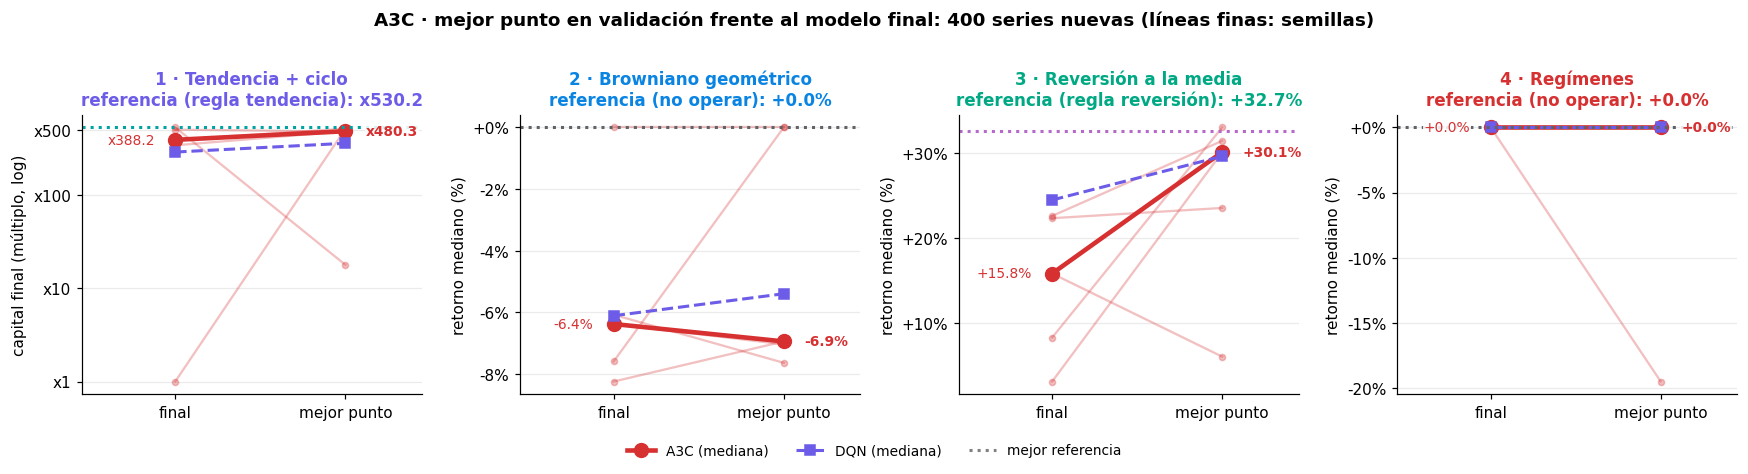

In [7]:
nb_ = csv("02_grid_nuevas_base")
nm_ = csv("02_grid_nuevas_mejor_punto")
dqn_b = csv("01_grid_mejora_nuevas_base").groupby("mercado").retorno_mediana.median()
dqn_m = csv("01_grid_mejora_mejor_punto_nuevas").groupby("mercado").retorno_mediana.median()
ref_n = csv("02_grid_nuevas_referencias").set_index("mercado").retorno_mediana

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, m in zip(axes, MERCADOS):
    t = np.log1p if m == "tendencia_ciclo" else (lambda r: 100 * np.asarray(r))  # log solo en el mercado 1
    b = nb_[nb_.mercado == m].sort_values("seed").retorno_mediana.to_numpy()
    e = nm_[nm_.mercado == m].sort_values("seed").retorno_mediana.to_numpy()
    for bi, ei in zip(b, e):
        ax.plot([0, 1], [t(bi), t(ei)], color=AGENT_COLORS["a3c"], alpha=0.3, marker="o", ms=4)
    ax.plot([0, 1], [t(np.median(b)), t(np.median(e))], color=AGENT_COLORS["a3c"], lw=3, marker="o", ms=9, label="A3C (mediana)")
    ax.plot([0, 1], [t(dqn_b[m]), t(dqn_m[m])], color=AGENT_COLORS["dqn"], lw=2, ls="--", marker="s", ms=6, label="DQN (mediana)")
    ax.axhline(t(ref_n[m]), color=AGENT_COLORS[MEJOR_REF[m]], ls=":", lw=2)
    ax.text(-0.12, t(np.median(b)), formato(np.median(b)), va="center", ha="right", fontsize=9, color=AGENT_COLORS["a3c"],
            bbox=dict(fc="white", ec="none", pad=0.5, alpha=0.85))
    ax.text(1.12, t(np.median(e)), formato(np.median(e)), va="center", ha="left", fontsize=9, fontweight="bold", color=AGENT_COLORS["a3c"],
            bbox=dict(fc="white", ec="none", pad=0.5, alpha=0.85))
    ax.set_xticks([0, 1], ["final", "mejor punto"])
    ax.set_xlim(-0.55, 1.45)
    if m == "tendencia_ciclo":
        ax.set_yticks(np.log1p([0, 9, 99, 499]), ["x1", "x10", "x100", "x500"])
        ax.set_ylabel("capital final (múltiplo, log)")
    else:
        ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=6, steps=[1, 2, 5, 10]))
        ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{v:+.0f}%"))
        ax.set_ylabel("retorno mediano (%)")
    ax.set_title(f"{MARKET_LABELS[m]}\nreferencia ({NOMBRES[MEJOR_REF[m]].lower()}): {formato(ref_n[m])}", color=MARKET_COLORS[m])
    ax.grid(axis="x", visible=False)
axes[0].plot([], [], color="gray", ls=":", lw=2, label="mejor referencia")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("A3C · mejor punto en validación frente al modelo final: 400 series nuevas (líneas finas: semillas)", fontweight="bold", y=1.02)
fig.tight_layout()
savefig(fig, "04_p2_mejor_punto")
plt.show()

| Mejora | Resultado | Veredicto |
|---|---|---|
| Normalizar observación y recompensa | Sin observación normalizada el 3 no opera | **Adoptada** (D-1.1) |
| Máscara de acciones redundantes | x491,2 frente a x728,1; +16,0 % frente a +25,9 % (validación) | **Rechazada** |
| Muestrear π en vez de la acción más probable | Baja el 1 (x318,2), sube el 3 (+16,7 %), pero opera mucho más | **No consistente** |
| Mejor punto en validación | 1: x388,2 → **x480,3**; 3: +15,8 % → **+30,1 %** (supera el margen en los dos) | **Funciona, no se adopta** (posterior al test) |

- El mejor punto **ayuda más a A3C que a DQN** (DQN: x287,4 → x356,7; +24,5 % → +29,6 %): su problema es acabar en un mal momento, no la capacidad.
- Aun así **no alcanza a las reglas** (x530,2 y +32,7 % en las mismas series), y en el 4 una semilla baja a −19,5 %.

**En resumen:** A3C aprende la estrategia esperada en 3 de 4 mercados solo con entropía, pero no bate a las reglas y queda por debajo de DQN en reversión. Su límite es la **estabilidad** (semillas que no operan, caída validación → test). El coste temporal frente a DQN está en **§4.2**.

## 3. Más allá de los mínimos

> **Evaluación posterior al test.** 400 series sintéticas nuevas por mercado (semillas desde 600 000), 5 semillas por condición y **un solo cambio** respecto a la referencia DQN del 03. No sustituye a los resultados de 01/02 (D-3.1, D-3.2).

**Ventaja log emparejada**: mediana entre semillas de la ventaja log por serie frente a la referencia, con las mismas series y semillas; el margen es el de siempre, en log. Es descriptivo, no un test de significación.

### 3.1 Qué variante mejora a la referencia y dónde

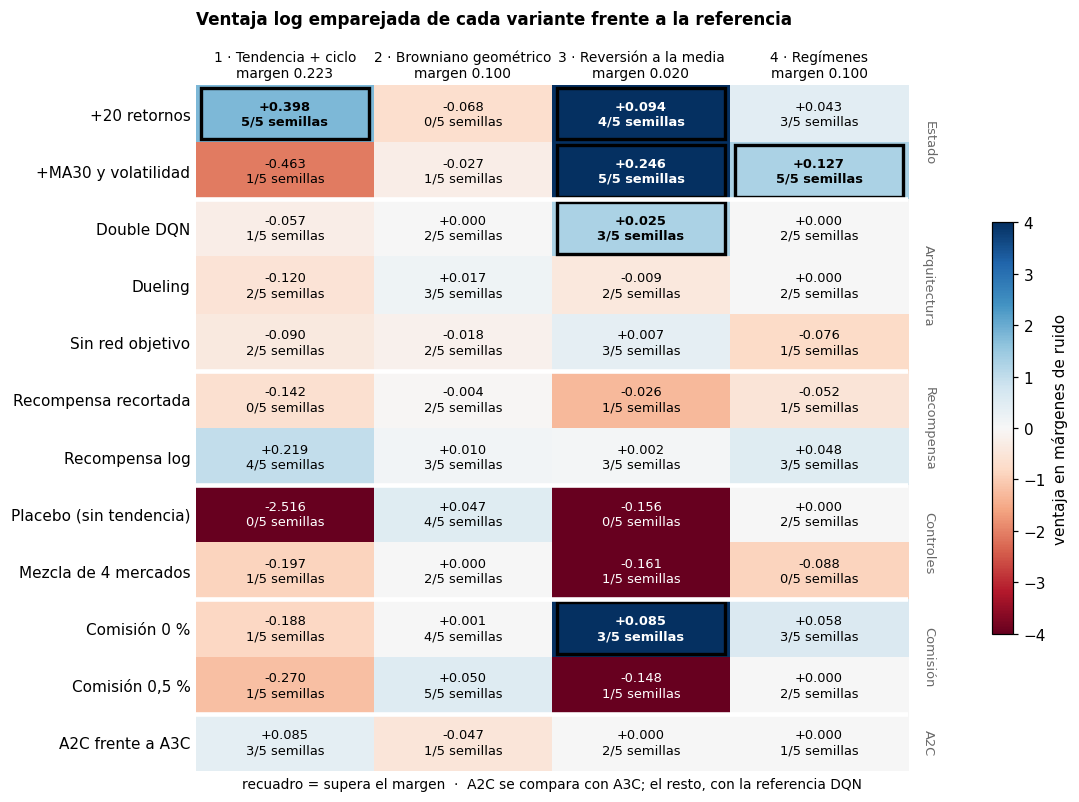

In [8]:
par = pd.concat([csv("03_grid_pareadas"), csv("03_grid_pareadas_actores")], ignore_index=True)
res3 = csv("03_grid_resumen_dqn")
bas3 = csv("03_extras_baselines")

GRUPOS = {
    "Estado": {"ventana": "+20 retornos", "ma30_vol": "+MA30 y volatilidad"},
    "Arquitectura": {"doble": "Double DQN", "duelo": "Dueling", "sin_objetivo": "Sin red objetivo"},
    "Recompensa": {"clip": "Recompensa recortada", "log": "Recompensa log"},
    "Controles": {"ciego": "Placebo (sin tendencia)", "mezcla": "Mezcla de 4 mercados"},
    "Comisión": {"comision_0": "Comisión 0 %", "comision_05": "Comisión 0,5 %"},
    "A2C": {"a2c": "A2C frente a A3C"},
}
filas = [(v, n) for d in GRUPOS.values() for v, n in d.items()]
ix = par.set_index(["variante", "mercado"])
margen = par.groupby("mercado").margen.first()
ratio = np.array([[ix.loc[(v, m), "ventaja_log"] / margen[m] for m in MERCADOS] for v, _ in filas])
textos = [[f"{ix.loc[(v, m), 'ventaja_log']:+.3f}\n{int(ix.loc[(v, m), 'semillas_mejoran'])}/{int(ix.loc[(v, m), 'n_semillas'])} semillas"
           for m in MERCADOS] for v, _ in filas]

fig, ax = plt.subplots(figsize=(10.5, 7.4))
im = heatmap(ax, np.clip(ratio, -4, 4), textos, [n for _, n in filas],
             [f"{MARKET_LABELS[m]}\nmargen {margen[m]:.3f}" for m in MERCADOS],
             separadores=np.cumsum([len(d) for d in GRUPOS.values()])[:-1])
for i, (v, _) in enumerate(filas):
    for j, m in enumerate(MERCADOS):
        if ix.loc[(v, m), "supera_margen"]:
            ax.add_patch(Rectangle((j - .47, i - .45), .94, .9, fill=False, ec="black", lw=2.2))
lims = np.r_[-.5, np.cumsum([len(d) for d in GRUPOS.values()]) - .5]
for y0, y1, g in zip(lims[:-1], lims[1:], GRUPOS):
    ax.text(3.58, (y0 + y1) / 2, g, rotation=-90, va="center", ha="left", fontsize=8.5, color="dimgray")
fig.colorbar(im, ax=ax, shrink=0.6, pad=0.09, label="ventaja en márgenes de ruido")
ax.set_xlabel("recuadro = supera el margen  ·  A2C se compara con A3C; el resto, con la referencia DQN", fontsize=9)
ax.set_title("Ventaja log emparejada de cada variante frente a la referencia", loc="left", pad=40)
fig.tight_layout()
savefig(fig, "04_p3_ventaja_emparejada")
plt.show()

- **El estado pesa más que la arquitectura.** Solo cambiar lo que ve el agente supera el margen de forma consistente: +20 retornos en tendencia (+0,398, 5/5) y reversión (+0,094, 4/5); MA30 + volatilidad en reversión (+0,246, 5/5) y regímenes (+0,127, 5/5). Ninguno es universal: ambos empeoran el browniano y MA30 + volatilidad hunde la tendencia (−0,463).
- **Arquitectura y recompensa apenas cambian nada**: Double DQN solo supera el margen en reversión (+0,025, 3/5); Dueling, sin red objetivo y recorte no lo superan en ninguno. La recompensa log se queda a las puertas en tendencia (+0,219 frente a 0,223).
- **Placebo**: sin tendencia el agente compra y mantiene (x26,6 en tendencia, como buy & hold; −2,516 en log): parte del retorno es deriva, pero la referencia sí extrae señal.
- **Mezcla** de los 4 generadores (mismo presupuesto, 125 episodios por mercado): peor que especializar; reversión +16,8 % → +0,1 %, regímenes −7,0 % → −16,1 %.
- **A2C frente a A3C** (mismos parámetros): no supera el margen en ningún mercado (x509,1 frente a x500,3 en tendencia).

### 3.2 Comisiones, mercados extra y S&P 500 real

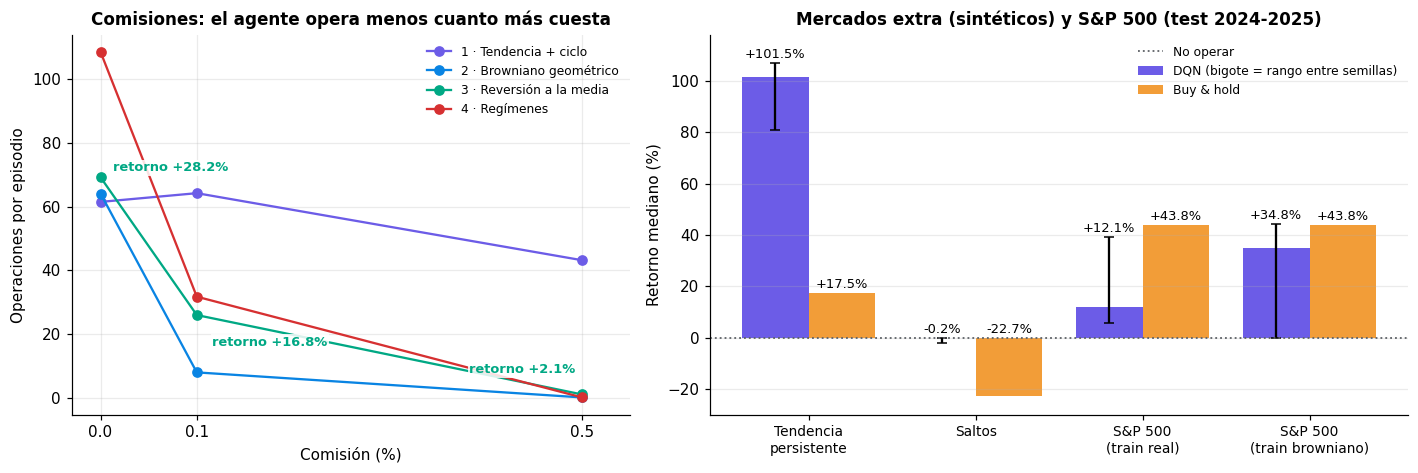

In [9]:
cv = {"comision_0": 0.0, "base": 0.1, "comision_05": 0.5}
com = res3[res3.variante.isin(cv) & res3.mercado.isin(MERCADOS)].assign(comision=lambda d: d.variante.map(cv))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.25]})
for m in MERCADOS:
    d = com[com.mercado == m].sort_values("comision")
    a1.plot(d.comision, d.operaciones, "o-", color=MARKET_COLORS[m], label=MARKET_LABELS[m])
d = com[com.mercado == "reversion_media"].sort_values("comision")
for (x, y, r), off, ha in zip(zip(d.comision, d.operaciones, d.mediana), [(8, 4), (10, -20), (-4, 14)], ["left", "left", "right"]):
    a1.annotate(f"retorno {formato(r)}", (x, y), xytext=off, textcoords="offset points", ha=ha,
                fontsize=8.5, color=MARKET_COLORS["reversion_media"], fontweight="bold",
                bbox=dict(fc="white", ec="none", pad=1, alpha=0.85))
a1.set(xticks=[0, .1, .5], xlim=(-0.03, 0.55), xlabel="Comisión (%)", ylabel="Operaciones por episodio",
       title="Comisiones: el agente opera menos cuanto más cuesta")
a1.legend(fontsize=8, loc="upper right")

casos = [("tendencia_persistente", "base", "Tendencia\npersistente"), ("saltos", "base", "Saltos"),
         ("sp500", "real", "S&P 500\n(train real)"), ("sp500", "transferencia", "S&P 500\n(train browniano)")]
bh = bas3[bas3.agente == "03_buy_hold_c0.001"].set_index("mercado").retorno_mediana
r3 = res3.set_index(["mercado", "variante"])
v = np.array([[r3.loc[(m, var), k] for k in ("mediana", "peor", "mejor")] for m, var, _ in casos]) * 100
b = np.array([bh[m] for m, *_ in casos]) * 100
x = np.arange(len(casos))
a2.bar(x - .2, v[:, 0], .4, color=AGENT_COLORS["dqn"], label="DQN (bigote = rango entre semillas)",
       yerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], capsize=3)
a2.bar(x + .2, b, .4, color=AGENT_COLORS["buy_hold"], label="Buy & hold")
for i in x:
    a2.text(i - .2, max(v[i, 2], 0) + 2, f"{v[i, 0]:+.1f}%", ha="center", fontsize=8.5)
    a2.text(i + .2, max(b[i], 0) + 2, f"{b[i]:+.1f}%", ha="center", fontsize=8.5)
a2.axhline(0, color=AGENT_COLORS["no_operar"], lw=1.2, ls=":", label="No operar")
a2.set(xticks=x, ylabel="Retorno mediano (%)", ylim=(-30, 118), title="Mercados extra (sintéticos) y S&P 500 (test 2024-2025)")
a2.set_xticklabels([n for *_, n in casos], fontsize=9)
a2.grid(axis="x", visible=False)
a2.legend(fontsize=8, loc="upper right")
fig.tight_layout()
savefig(fig, "04_p3_comisiones_y_mercados_extra")
plt.show()

- **Comisiones**: cambian la tarea, no el algoritmo (por eso comisión 0 % “supera” el margen en reversión). En reversión, con 0 % · 0,1 % · 0,5 %: 69,2 → 25,9 → 1,0 operaciones y +28,2 % → +16,8 % → +2,1 %.
- **Mercados extra**: en tendencia persistente DQN gana +101,5 % frente a +17,5 % de buy & hold; en saltos casi deja de operar (−0,2 % frente a −22,7 %). Aprovecha tendencias observables, no shocks independientes.
- **S&P 500 real** (train 2017-2021, test 2024-2025): +12,1 % con 75 operaciones frente a +43,8 % de buy & hold. Transferir desde el browniano da +34,8 % (rango 0 % a +44,3 %): en la práctica, comprar y mantener. Una sola trayectoria: 5 semillas no son 5 pruebas independientes.

**En resumen:** lo que más mejora a DQN es **qué ve** (estado), no **cómo aprende** (Double, Dueling, red objetivo, recompensa), y ninguna mejora es universal. Los controles acotan el alcance: parte del retorno en tendencia es deriva y en datos reales no se bate a buy & hold.

## 4. Comparativa final (ejercicio 4)

### 4.1 Tabla de rendimiento

Retorno mediano en las 200 series de test; DQN y A3C, mediana entre 5 semillas. Color = posición dentro de cada mercado (verde, mejor); recuadro = mejor del mercado.

In [10]:
FAMILIA = {"aleatorio": "Baseline", "buy_hold": "Baseline", "no_operar": "Baseline", "regla_tendencia": "Regla", "regla_reversion": "Regla",
           "qlearning": "Tabular (T1)", "sarsa": "Tabular (T1)", "dqn": "Deep RL", "a3c": "Deep RL"}
vista = TABLA.copy()
vista.index = pd.MultiIndex.from_tuples([(FAMILIA[a], NOMBRES[a]) for a in ORDEN], names=["", "Agente"])
vista.columns = [MARKET_LABELS[m] for m in MERCADOS]
(vista.style
    .format(formato)
    .background_gradient(cmap="RdYlGn", axis=None, gmap=vista.rank(axis=0, method="average").to_numpy(), vmin=1, vmax=len(vista))
    .highlight_max(axis=0, props="font-weight:bold; border:2px solid black")
    .set_properties(**{"text-align": "center", "min-width": "110px"})
    .set_caption("Retorno mediano en test (recuadro = mejor del mercado)"))

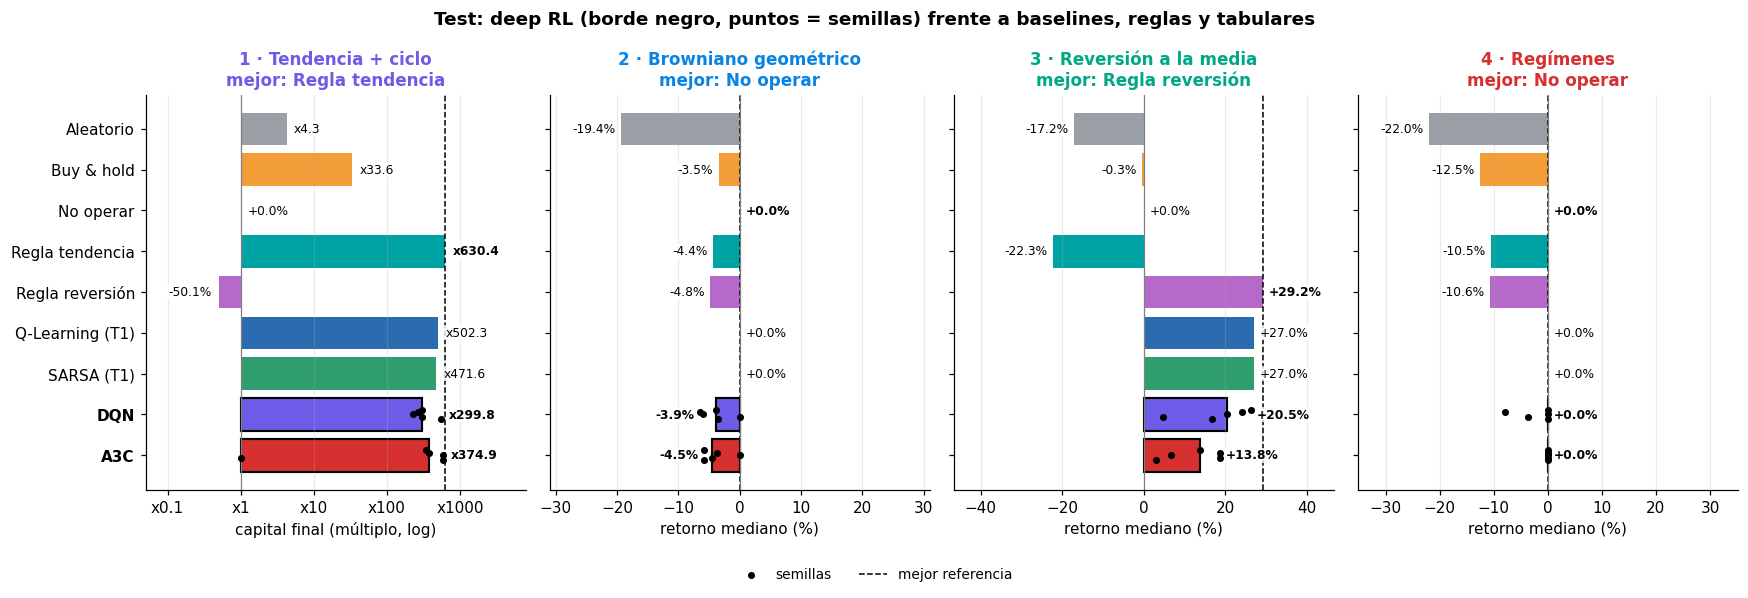

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5.2), sharey=True)
y = np.arange(len(ORDEN))
for ax, m in zip(axes, MERCADOS):
    r = TABLA[m].to_numpy()
    log = m == "tendencia_ciclo"
    tr = (lambda v: 1 + np.asarray(v)) if log else (lambda v: 100 * np.asarray(v))
    origen = 1 if log else 0
    ax.barh(y, tr(r) - origen, left=origen, color=[AGENT_COLORS[a] for a in ORDEN],
            edgecolor=["black" if a in ("dqn", "a3c") else "none" for a in ORDEN], linewidth=1.4)
    extremos = {}
    for a in ("dqn", "a3c"):  # semillas
        s = tr(SEMILLAS[(SEMILLAS.agente == a) & (SEMILLAS.mercado == m)].retorno_mediana.to_numpy())
        ax.scatter(s, np.full(len(s), ORDEN.index(a)) + np.linspace(-0.12, 0.12, len(s)), color="black", s=13, zorder=3,
                   label="semillas" if a == "dqn" else None)
        extremos[a] = (s.min(), s.max())
    ax.axvline(tr(TABLA.loc[MEJOR_REF[m], m]), color="black", ls="--", lw=1, label="mejor referencia")
    ax.axvline(origen, color="grey", lw=0.8)
    if log:
        ax.set_xscale("log")
        ax.set_xticks([0.1, 1, 10, 100, 1000], ["x0.1", "x1", "x10", "x100", "x1000"])
        ax.minorticks_off()
        ax.set_xlim(0.05, 8000)
        ax.set_xlabel("capital final (múltiplo, log)")
    else:
        lim = max(abs(tr(r)).max(), max(np.abs(np.array(e)).max() for e in extremos.values())) * 1.6
        ax.set_xlim(-lim, lim)
        ax.set_xlabel("retorno mediano (%)")
    for yi, a, ri in zip(y, ORDEN, r):
        v = tr(ri)
        derecha = v >= origen
        if a in extremos:
            v = max(v, extremos[a][1]) if derecha else min(v, extremos[a][0])
        pos = v * (1.25 if derecha else 1 / 1.25) if log else v + (1 if derecha else -1) * 0.03 * lim
        ax.text(pos, yi, formato(ri), va="center", ha="left" if derecha else "right", fontsize=8, zorder=4,
                fontweight="bold" if a in ("dqn", "a3c", MEJOR_REF[m]) else "normal", bbox=dict(fc="white", ec="none", pad=0.6, alpha=0.8))
    ax.set_title(f"{MARKET_LABELS[m]}\nmejor: {NOMBRES[TABLA[m].idxmax()]}", color=MARKET_COLORS[m])
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, [NOMBRES[a] for a in ORDEN])
for lab in axes[0].get_yticklabels():
    if lab.get_text() in ("DQN", "A3C"):
        lab.set_fontweight("bold")
axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Test: deep RL (borde negro, puntos = semillas) frente a baselines, reglas y tabulares", fontweight="bold")
fig.tight_layout(rect=(0, 0.03, 1, 1))
savefig(fig, "04_p4_comparativa_mercados")
plt.show()

- **Ningún agente de deep RL gana en ningún mercado.** El mejor es siempre una regla simple (x630,4 en tendencia y +29,2 % en reversión) o no operar (mercados 2 y 4).
- **Los tabulares del Taller 1 quedan por encima de DQN y A3C** donde hay señal: x502,3 frente a x299,8 / x374,9 y +27,0 % frente a +20,5 % / +13,8 %.
- **Sí baten con claridad a buy & hold y al aleatorio** con señal (buy & hold: x33,6 y −0,3 %).
- **Sin señal, lo correcto es no operar**: lo consiguen en regímenes (+0,0 %); en el browniano DQN y A3C entran y se quedan (−3,9 % y −4,5 %, ≈ buy & hold).
- **Las semillas se solapan**: la dispersión de cada agente (DQN: x228,4 a x557,8; A3C: de +0,0 %, una semilla que no opera, a x594,4) es mayor que la diferencia DQN–A3C.

### 4.2 Convergencia y tiempo

Criterio D-0.3 sobre la curva sin exploración: primer episodio que recorre el 90 % del camino hasta el nivel final; mediana entre las semillas que convergen. Tiempos en el **mismo equipo**: DQN se reentrenó en el equipo del A3C solo para medir el tiempo (`02_grid_tiempo_dqn`) y su tiempo hasta converger se reescala con ese factor. Los tabulares usan el criterio online del Taller 1 y otro equipo: solo orientativos.

In [12]:
t_dqn = csv("02_grid_tiempo_dqn").tiempo_s.median()  # DQN en el equipo del A3C
dqn_ = csv("01_grid_final")
factor = t_dqn / dqn_.tiempo_s.median()
SEM = pd.concat([dqn_.assign(tiempo_s=dqn_.tiempo_s * factor, tiempo_convergencia_s=dqn_.tiempo_convergencia_s * factor),
                 csv("02_grid_final")], ignore_index=True)
PASOS = 500 * (N_STEPS - 6)  # pasos de entorno en 500 episodios


def resumen(g):
    c = g[g.estado_convergencia == "converge"]
    otros = g.estado_convergencia[g.estado_convergencia != "converge"].value_counts()
    return pd.Series({
        "Convergen": f"{len(c)}/{len(g)}",
        "Episodios": c.episodios_convergencia.median(),
        "Pasos (miles)": c.pasos_convergencia.median() / 1e3,
        "s hasta converger": c.tiempo_convergencia_s.median(),
        "s entrenamiento": g.tiempo_s.median(),
        "Resto": ", ".join(f"{n} {k}" for k, n in otros.items()) or "—",
    })


conv = SEM.groupby(["agente", "mercado"]).apply(resumen, include_groups=False)
conv_t1 = tabulares.set_index(["agente", "mercado"])[["episodios_convergencia", "tiempo_s"]].rename(
    columns={"episodios_convergencia": "Episodios", "tiempo_s": "s entrenamiento"}).assign(Convergen="—", Resto="criterio online (T1)")
conv = pd.concat([conv, conv_t1]).reindex(pd.MultiIndex.from_product([["dqn", "a3c", "qlearning", "sarsa"], MERCADOS]))
CONV = conv.copy()
conv.index = conv.index.map(lambda i: (NOMBRES[i[0]], MARKET_LABELS[i[1]]))
(conv.style
    .format({"Episodios": "{:.0f}", "Pasos (miles)": "{:.0f}", "s hasta converger": "{:.1f}", "s entrenamiento": "{:.1f}"}, na_rep="—")
    .background_gradient(cmap="Greens_r", subset=["Episodios"])
    .background_gradient(cmap="Blues_r", subset=["s entrenamiento"])
    .set_caption("Convergencia por agente y mercado (— = ninguna semilla converge o no aplica)"))

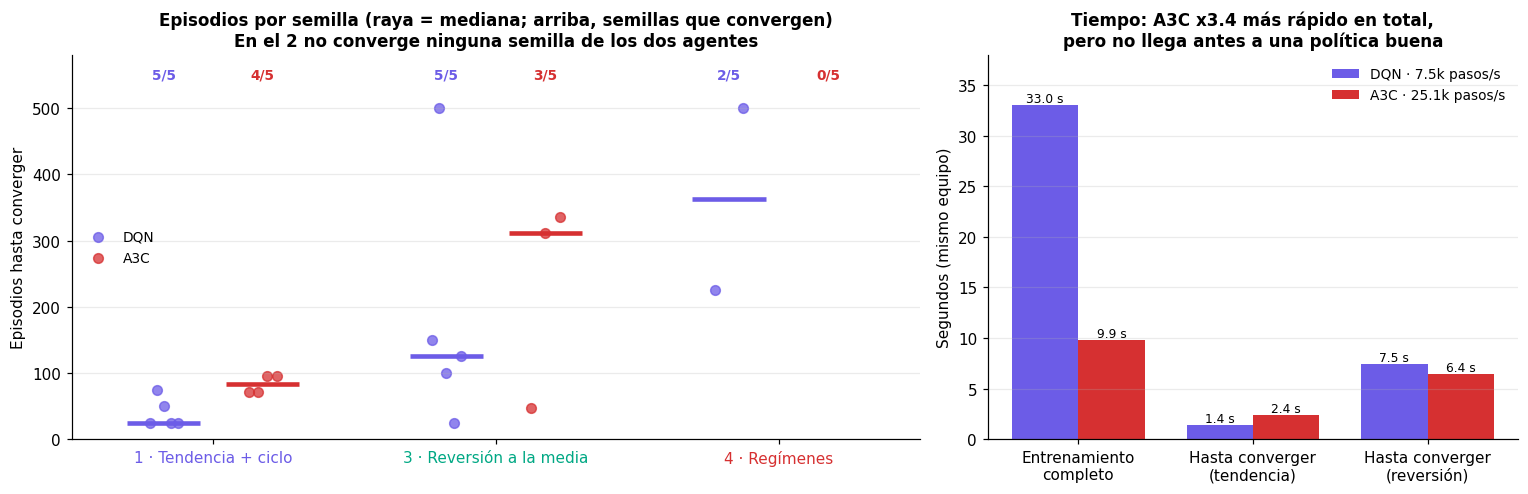

In [13]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
mc = ["tendencia_ciclo", "reversion_media", "regimenes"]
for k, ag in enumerate(["dqn", "a3c"]):
    d = SEM[(SEM.agente == ag) & (SEM.estado_convergencia == "converge")]
    for j, m in enumerate(mc):
        e = d[d.mercado == m].episodios_convergencia.to_numpy()
        x = j + (k - 0.5) * 0.35
        a1.scatter(np.full(len(e), x) + np.linspace(-0.05, 0.05, len(e)), e, color=AGENT_COLORS[ag], s=40, alpha=0.75,
                   label=NOMBRES[ag] if j == 0 else None)
        if len(e):
            a1.hlines(np.median(e), x - 0.13, x + 0.13, color=AGENT_COLORS[ag], lw=3)
        a1.text(x, 545, f"{len(e)}/5", ha="center", color=AGENT_COLORS[ag], fontweight="bold", fontsize=9)
a1.set_xticks(range(len(mc)), [MARKET_LABELS[m] for m in mc])
for lab, m in zip(a1.get_xticklabels(), mc):
    lab.set_color(MARKET_COLORS[m])
a1.set(ylim=(0, 580), xlim=(-0.5, 2.5), ylabel="Episodios hasta converger")
a1.set_title("Episodios por semilla (raya = mediana; arriba, semillas que convergen)\nEn el 2 no converge ninguna semilla de los dos agentes")
a1.grid(axis="x", visible=False)
a1.legend(loc="center left")

t_a3c = SEM[SEM.agente == "a3c"].tiempo_s.median()
vel = pd.DataFrame({"total": [t_dqn, t_a3c],
                    "tend": [CONV.loc[(a, "tendencia_ciclo"), "s hasta converger"] for a in ("dqn", "a3c")],
                    "rev": [CONV.loc[(a, "reversion_media"), "s hasta converger"] for a in ("dqn", "a3c")]}, index=["dqn", "a3c"])
xs = np.arange(vel.shape[1])
for k, ag in enumerate(vel.index):
    t_ag = t_dqn if ag == "dqn" else t_a3c
    bars = a2.bar(xs + (k - 0.5) * 0.38, vel.loc[ag], 0.38, color=AGENT_COLORS[ag], label=f"{NOMBRES[ag]} · {PASOS / t_ag / 1000:.1f}k pasos/s")
    a2.bar_label(bars, fmt="%.1f s", fontsize=8)
a2.set_xticks(xs, ["Entrenamiento\ncompleto", "Hasta converger\n(tendencia)", "Hasta converger\n(reversión)"])
a2.set_ylabel("Segundos (mismo equipo)")
a2.set_ylim(0, vel.max().max() * 1.15)
a2.set_title(f"Tiempo: A3C x{t_dqn / t_a3c:.1f} más rápido en total,\npero no llega antes a una política buena")
a2.grid(axis="x", visible=False)
a2.legend(loc="upper right")
fig.tight_layout()
savefig(fig, "04_p4_convergencia")
plt.show()

| Criterio | DQN | A3C | Mejor |
|---|---|---|---|
| Retorno en tendencia (1) | x299,8 | x374,9 | Empate (diferencia = margen de ruido, semillas solapadas) |
| Retorno en reversión (3) | +20,5 % | +13,8 % | **DQN** (6,7 puntos, margen 2) |
| Sin señal (2 y 4) | −3,9 % · +0,0 % (2/5 semillas pierden en el 4) | −4,5 % · +0,0 % (no opera en 5/5) | Empate; A3C más limpio en el 4 |
| Semillas que convergen (1 y 3) | 10/10, en 25 y 125 episodios | 7/10, en 84 y 312 episodios | **DQN** |
| Tiempo de entrenamiento (500 episodios) | 33,0 s (7,5k pasos/s) | 9,9 s (25,1k pasos/s) | **A3C**, x3,4 |
| Tiempo hasta converger (1 / 3) | 1,4 s / 7,5 s | 2,4 s / 6,4 s | Empate |

- **DQN es más eficiente por episodio y más estable; A3C, por segundo.** Sin *replay* ni red objetivo cada paso de A3C es barato y los 3 procesos escalan, pero necesita más episodios y converge menos veces: en segundos hasta una política buena, empatan.
- Ningún tiempo incluye evaluaciones; el de A3C tampoco el arranque de procesos. DQN se cronometró con 1 semilla por mercado.

## 5. Análisis crítico y conclusiones

**Limitaciones**

- **Estado de 2 variables** (`[tendencia/σ, posición]`): limita más que el algoritmo. Añadir 20 retornos lleva DQN de x348,4 a x547,9 en tendencia, y MA30 + volatilidad de +16,8 % a +47,9 % en reversión (§3.1); los cambios de arquitectura y recompensa no superan el margen salvo Double DQN en reversión, por poco.
- **Márgenes descriptivos, no tests.** 5 semillas, hiperparámetros ajustados uno a uno con 3 y muchas comparaciones. La dispersión entre semillas es del orden de la diferencia DQN–A3C (§4.1).
- **Mercados sintéticos** con la señal en una sola variable: miden si el agente encuentra una regla conocida, no si funcionaría en un mercado real. Ni el placebo ni la mezcla de generadores dan una política general (§3.1).
- **S&P 500: una sola trayectoria** (§3.2): +12,1 % frente a +43,8 % de buy & hold; el periodo ya se había visto en el Taller 1.
- **Coste fijo del 0,1 %**, sin deslizamiento ni *spread*; la comisión cambia la tarea (§3.2).
- **Convergencia ≠ estabilidad**: el 90 % del nivel final no implica una política estable (2 semillas de DQN “convergen” en regímenes a perder). Los tabulares usan otro criterio y otro equipo.

**Conclusiones**

1. **Deep RL aprende las estrategias correctas, pero no las mejora.** DQN y A3C siguen la tendencia (x299,8 y x374,9) y compran tras caídas (+20,5 % y +13,8 %), lejos de las reglas de un umbral (x630,4 y +29,2 %) y de Q-Learning (x502,3 y +27,0 %).
2. **Con 2 variables de estado, la red no aporta frente a la tabla Q.** La función continua solo gana al ampliar el estado (x547,9 y +47,9 % en el 03): esa es la palanca real, no la arquitectura.
3. **DQN es más estable y eficiente por episodio; A3C, x3,4 más rápido por segundo**, pero llega a la política buena en tiempos parecidos y converge en 7/10 semillas frente a 10/10.
4. **El límite de los dos es la estabilidad, no la capacidad**: quedarse con el mejor punto en validación los acerca a las reglas (A3C: x480,3 y +30,1 % en series nuevas), aunque sin alcanzarlas.
5. **Saber no operar es tan importante como operar.** En regímenes ambos acaban en +0,0 % frente a −12,5 % de buy & hold; en el browniano se quedan dentro porque la recompensa (retorno simple) favorece estar dentro.
6. **No es extrapolable a inversión real**: en el S&P 500, +12,1 % frente a +43,8 % de buy & hold, con una sola trayectoria y comisión fija.